In [ ]:
#step-1 load the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("credit_risk_dataset.csv")
df.shape






In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
#EDA exploratory data analaysis

df.shape
df.info()

In [ ]:
df.head()

In [ ]:
#First handle missing values



df.duplicated().sum()  #so here we have duplicate 165 rows of np.int64(165)
df.isnull().sum()  #here we can see that person_emp_length is 895 null values and loan_init_rate is 3116 null values

In [ ]:
(df['person_emp_length'] > 50).sum()

In [ ]:
df.head()

In [ ]:
#so here we are filling that value with NAN first

df.loc[df['person_emp_length']>50,'person_emp_length'] = np.nan

df['loan_intent'].unique()

df['person_age'].unique()

df['person_income'].nunique()




In [ ]:
#second column checking

(df['person_income']>0).sum()

df['person_income'].skew()      #Positive result → Right-skewed,#Negative result → Left-skewed,nearzero - little skewness









In [ ]:
#third column

df['person_home_ownership'].value_counts() #having unique values 4
df['person_home_ownership'].isnull().sum() #no rows are empty
#here we have planned the one hot encoding here


In [ ]:
#fourth column

df['person_emp_length'].isnull().sum()   #still 897 rows are missing or null
# df['person_emp_length'].value_counts()  #there are reasonable emptlength  upto 40 years and i think this is good for now .
#cross -feature consistency

df[(df['person_age']-df['person_emp_length'])<16]

(df['person_emp_length'] > df['person_age']).sum()

#median values are still pending there are some values here we need to check that also


In [ ]:
#fifth column


df['loan_intent'].value_counts() #no null values are missing values


df[(df['person_age']>35)& (df['loan_intent']=="EDUCATION")]

percentage = (532 /32581)*100
percentage
#Suppose you want to calculate the percentage of MEDICAL loan applicants who are older than 40.

percentage = (
    (df['loan_intent']=="MEDICAL").sum()/(df['person_age']>40).sum()
)*100
percentage

In [ ]:
#sixth column

#it is ordinal encoding


In [ ]:
#7th column loan amount

df.head()



In [ ]:
df['loan_amnt'].value_counts()
df['loan_grade'].isnull().sum()

In [ ]:
#8th column

df['loan_int_rate'].isnull().sum() #missing rows

df['loan_int_rate'].skew() #positive skewness so mean and median are almost near because value is near to 0 mostly near to normal distribution

df['loan_int_rate'].value_counts(ascending=True)

import matplotlib.pyplot as plt

df.hist(column = 'loan_int_rate',bins = 50)
plt.show()
df['loan_int_rate'].describe()

In [ ]:
df.head()

In [ ]:
#nineth column

df['loan_status'].value_counts()

In [ ]:
#10th column


df['loan_percent_income'].value_counts()
df['loan_percent_income'].isnull().sum()

In [ ]:
df.loc[
    (df['person_age'] - df['cb_person_cred_hist_length']) < 18,
    ['person_age', 'cb_person_cred_hist_length']
]

In [ ]:
df['loan_status']

sns.countplot(x = df['loan_status'])

In [ ]:
sns.boxplot(x = df['person_age'])

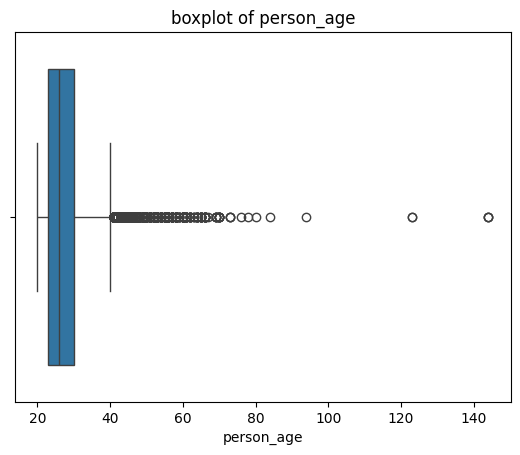

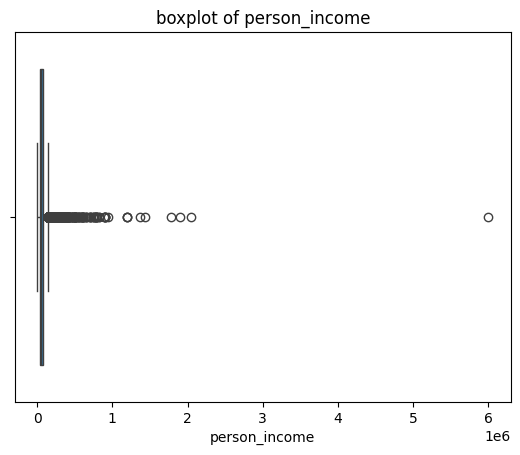

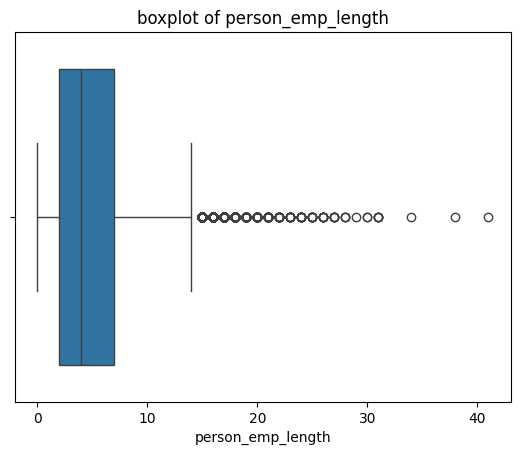

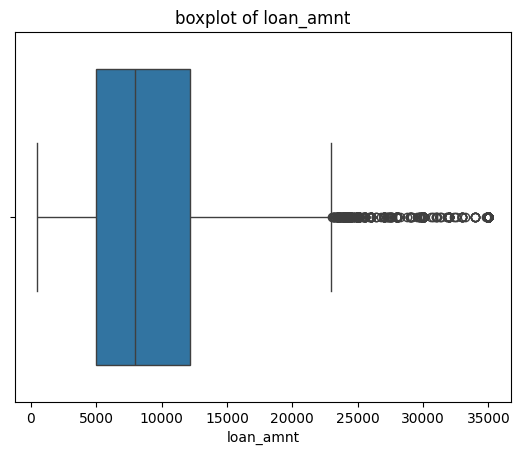

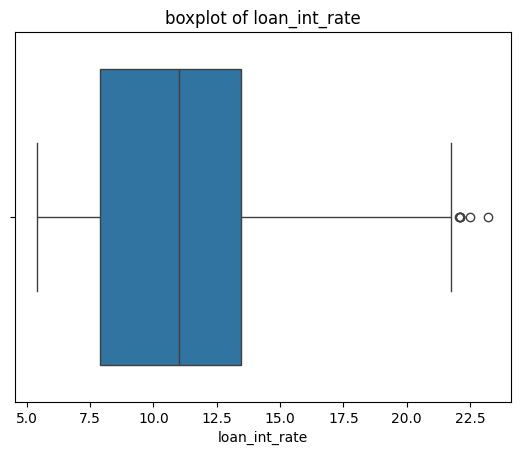

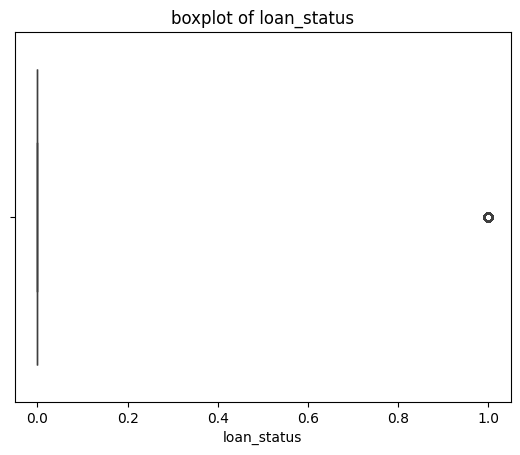

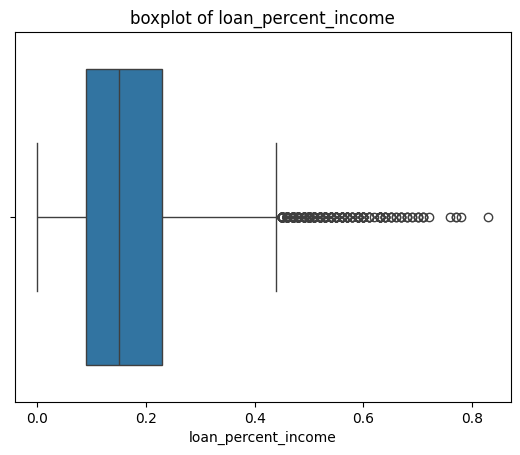

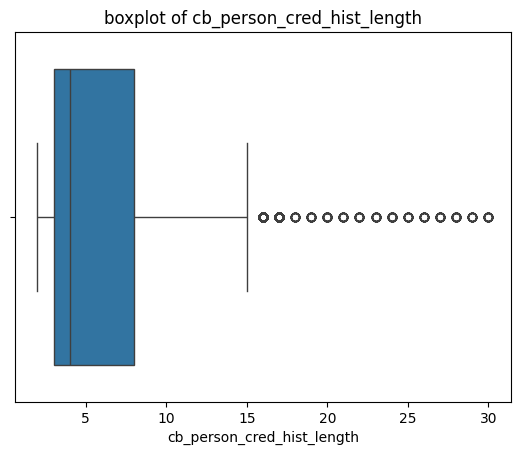

In [ ]:
numeric_cols = df.select_dtypes(include = 'number').columns
numeric_cols
for i in numeric_cols:
  sns.boxplot(x = df[i])
  plt.title(f'boxplot of {i}')
  plt.show()


In [ ]:
numeric_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

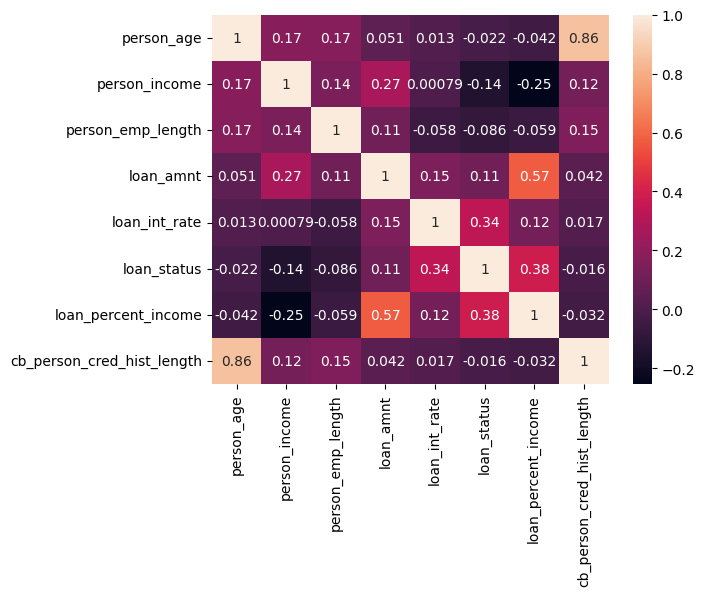

In [ ]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

In [ ]:
df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,NaN,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.0,PERSONAL,C,5800,13.16,0,0.11,N,30
32577,54,120000,MORTGAGE,4.0,PERSONAL,A,17625,7.49,0,0.15,N,19
32578,65,76000,RENT,3.0,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5.0,PERSONAL,B,15000,11.48,0,0.10,N,26


In [ ]:
#step 3 data validation and outlier handling

df_copy = df.copy()
print(f"after copy {df_copy.shape}")

df_copy = df_copy.drop_duplicates()
print(f"after dropping duplicatess copy {df_copy.shape}")

#so here we have 166rows something around which are duplicatess

df_copy

# Corrected the boolean indexing syntax using & and referencing df_copy['person_age']
df_copy = df_copy[(df_copy['person_age'] > 18) & (df_copy['person_age'] < 101)]
print(f"after removing age outliers copy {df_copy.shape}")

#next removing emplength whose greater than age


df_copy = df_copy[ (df_copy['person_emp_length']) <= (df_copy['person_age'])]

df_copy = df_copy[ (df_copy['person_emp_length']) <= 60]
print(f"after removing invalid emptlengthe outliers copy {df_copy.shape}")

df_copy = df_copy[(df_copy['person_income'])>0]


print(f"after removing invalid emptlengthe outliers copy {df_copy.shape}")




after copy (32581, 12)
after dropping duplicatess copy (32416, 12)
after removing age outliers copy (32411, 12)
after removing invalid emptlengthe outliers copy (31522, 12)
after removing invalid emptlengthe outliers copy (31522, 12)


In [ ]:
#feature engineering


x = df_copy.drop(columns = ['loan_status'])
y = df_copy['loan_status']

x.shape
y.shape

(31522,)

In [ ]:
#feature engineering

from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2 ,stratify = y,random_state = 42)

In [ ]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                'loan_int_rate', 'loan_percent_income',
                'cb_person_cred_hist_length']

category_cols = ['person_home_ownership', 'loan_intent', 'loan_grade',
                  'cb_person_default_on_file']



In [ ]:
#class imbalance

class0, class1 = np.bincount(y_train)
print(class0,class1)

scaled_weights = class0/class1
scaled_weights

19772 5445


np.float64(3.6312213039485766)

In [ ]:
#pipeline
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer


numeric_transformer = Pipeline(
    steps = [
        ('imputer',SimpleImputer(strategy = 'median')),
        ('scaler',StandardScaler())
    ]
)
categorical_transformer = Pipeline(
    steps = [
        ('imputer',SimpleImputer(strategy = 'most_frequent')),
        ('onehot',OneHotEncoder(handle_unknown = 'ignore'))
    ]
)

lg_preprocessor = ColumnTransformer(
    transformers = [
        ('num',numeric_transformer,numeric_cols),
        ('cat',categorical_transformer,category_cols)
    ]
)






In [ ]:
#XG BOOST Preporxoecssing


Xgnumeric_transformer = Pipeline(
    steps = [
        ('imputer',SimpleImputer(strategy = 'median'))
    ]
)

Xgcategorical_transformer = Pipeline(
    steps = [
        ('imputer',SimpleImputer(strategy = 'most_frequent')),
        ('onehot',OneHotEncoder(handle_unknown = 'ignore'))

    ]
)

Xgpreprocessor = ColumnTransformer(
    transformers = [
        ('num',Xgnumeric_transformer,numeric_cols),
        ('cat',Xgcategorical_transformer,category_cols)
    ]
)






In [ ]:
#Stratified Cross Validation

from sklearn.model_selection import StratifiedKFold



cv = StratifiedKFold(n_splits = 5 ,shuffle = True , random_state = 42)

scoring = {'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1','roc_auc':'roc_auc'}



In [ ]:
#model building and train it on all these factors

from sklearn.linear_model import LogisticRegression

lr_cv_pipeline = Pipeline(
    [
        ('preprocessor', lg_preprocessor),
        ('classifier', LogisticRegression(class_weight = 'balanced',random_state = 42,max_iter = 1000))
    ]
)
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [ ]:
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

xgb_cv_pipeline = Pipeline(
    [
        ('preprocessor',Xgpreprocessor),
        ('classifier',XGBClassifier(n_estimators = 300,learning_rate = 0.01,max_depth = 5 ,random_state = 42 , scale_pos_weight = scaled_weights,n_jobs = -1 ))
    ]
)
xgb_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.01,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [ ]:
# now you need to train a model right
from sklearn.model_selection import cross_validate

for cv_name ,pipeline in [('logistic_regression',lr_cv_pipeline),('xgboostpipeline',xgb_cv_pipeline)]:
  cv_results =  cross_validate(pipeline,x_train,y_train,cv = cv,scoring = scoring,n_jobs= -1)
  print(f"\ntraining_cvname",cv_name)
  print(f"test_accuracy,{cv_results['test_accuracy'].mean():3f}")
  print(f"precision,{cv_results['test_precision'].mean():3f}")
  print(f"recall,{cv_results['test_recall'].mean():3f}")
  print(f"f1,{cv_results['test_f1'].mean():3f}")
  print(f"roc_auc,{cv_results['test_roc_auc'].mean():3f}")

  print("-"*50)






training_cvname logistic_regression
test_accuracy,0.811595
precision,0.544823
recall,0.778145
f1,0.640801
roc_auc,0.870511
--------------------------------------------------

training_cvname xgboostpipeline
test_accuracy,0.888250
precision,0.729906
recall,0.766942
f1,0.747773
roc_auc,0.923448
--------------------------------------------------


In [ ]:
#evaluate function
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve
)

def evaluatefunction(modelname, model, x_test, y_test,threshold  = None):

  y_prob = model.predict_proba(x_test)[:,1]

  if threshold is not None:
    y_pred = (y_prob > threshold).astype(int)
  else:
    y_pred = model.predict(x_test)

  accuracy = accuracy(y_test, y_pred)
  precision = precision_score(y_test, y_pred)
  recall = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  roc_auc = roc_auc_score(y_test, y_prob)
  classificationreport = classification_report(y_test, y_pred)
  confusionmatrix = confusion_matrix(y_test, y_pred)

  print(f"modelname:{modelname}")
  print(f"accuracy:{accuracy:.2f}")
  print(f"precision:{precision:.2f}")
  print(f"recall:{recall:.2f}")
  print(f"f1:{f1:.2f}")
  print(f"roc_auc:{roc_auc:.2f}")
  print(f"classificationreport:\n{classificationreport}")
  print(f"confusionmatrix:\n{confusionmatrix}")

  # Confusion Matrix Plot
  plt.figure(figsize=(8,6))
  sns.heatmap(confusionmatrix, annot=True, fmt='d', cmap='Blues')
  plt.title(f'Confusion Matrix for {modelname}')
  plt.ylabel('Actual')
  plt.xlabel('Predicted')
  plt.show()

  # Precision-Recall Curve Plot
  precisions, recalls, thresholds = precision_recall_curve(y_test, y_prob)
  plt.figure(figsize=(8,6))
  plt.plot(recalls, precisions, label=f'{modelname} (AUC = {roc_auc:.2f})')
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{modelname} Precision-Recall Curve")
  plt.legend(loc="lower left")
  plt.grid(True)
  plt.show()


In [ ]:
#baseline model

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Restoring the metric calculations and print statements inside the evaluate function
def evaluatefunction(modelname, model, x_test, y_test):
  y_pred = model.predict(x_test)
  y_prob = model.predict_proba(x_test)[:,1]

  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred)
  recall_val = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  roc_auc = roc_auc_score(y_test, y_prob)

  print(f"modelname:{modelname}")
  print(f"accuracy:{accuracy:.2f}")
  print(f"precision:{precision:.2f}")
  print(f"recall:{recall_val:.2f}")
  print(f"f1:{f1:.2f}")
  print(f"roc_auc:{roc_auc:.2f}")

baseline_model = Pipeline(
    [
        ('preprocessor',lg_preprocessor),
        ('classifier',LogisticRegression(class_weight = 'balanced',random_state= 42))
    ]
)
baseline_model.fit(x_train,y_train)
evaluatefunction('baseline_model',baseline_model,x_test,y_test)

modelname:baseline_model
accuracy:0.82
precision:0.56
recall:0.79
f1:0.65
roc_auc:0.88


In [ ]:
#actual better model XGBOOST

from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Restoring the metric calculations and print statements inside the evaluate function
def evaluatefunction(modelname, model, x_test, y_test):
  y_pred = model.predict(x_test)
  y_prob = model.predict_proba(x_test)[:,1]

  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred)
  recall_val = recall_score(y_test, y_pred)
  f1 = f1_score(y_test, y_pred)
  roc_auc = roc_auc_score(y_test, y_prob)

  print(f"modelname:{modelname}")
  print(f"accuracy:{accuracy:.2f}")
  print(f"precision:{precision:.2f}")
  print(f"recall:{recall_val:.2f}")
  print(f"f1:{f1:.2f}")
  print(f"roc_auc:{roc_auc:.2f}")

Xgb_model = Pipeline(
    [
        ('preprocessor',Xgpreprocessor),
        ('classifier',XGBClassifier(scale_pos_weight = scaled_weights,learning_rate=0.01,random_state=42))
    ]
)
Xgb_model.fit(x_train,y_train)
evaluatefunction('xgboost',Xgb_model,x_test,y_test)

modelname:xgboost
accuracy:0.89
precision:0.74
recall:0.76
f1:0.75
roc_auc:0.93


In [ ]:
#now hyper parameter tuning

from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint,uniform

parameter_grid = {
    'classifier__n_estimators': randint(150, 600),
    'classifier__max_depth': randint(1, 9),
    'classifier__learning_rate': uniform(0.01, 0.49),
    'classifier__subsample': uniform(0.5, 0.5),
    'classifier__colsample_bytree': uniform(0.5, 0.5),
    'classifier__gamma': uniform(0,5),
    'classifier__min_child_weight': randint(1, 10)
}

random_search = RandomizedSearchCV(Xgb_model,parameter_grid,n_iter= 150 ,scoring = 'average_precision',cv = cv ,verbose = 1 ,n_jobs=-1)


random_search.fit(x_train,y_train)
random_search.best_params_

Fitting 5 folds for each of 150 candidates, totalling 750 fits


{'classifier__colsample_bytree': np.float64(0.8966141227821758),
 'classifier__gamma': np.float64(1.4936278234115523),
 'classifier__learning_rate': np.float64(0.0290484164249995),
 'classifier__max_depth': 7,
 'classifier__min_child_weight': 4,
 'classifier__n_estimators': 560,
 'classifier__subsample': np.float64(0.8314455980362057)}

In [ ]:
score = random_search.best_score_
score

np.float64(0.9035574535086811)

In [ ]:
#threshold selection using precision ,recall and f1

#get the probablilit from xgboost class 1
#calculate the precision  and recall for each threshold and  calucualtethe f1 score at each threshold

#evaluate the xgboost model using that threshold

prob = Xgb_model.predict_proba(x_test)[:, 1]
prob

precision, recalls, thresholds = precision_recall_curve(y_test, prob)

# Correct formula for F1 scores
f1_scores = (2 * precision * recalls) / (precision + recalls + 1e-9)

best = np.argmax(f1_scores[:-1])

best_threshold = thresholds[best]
print(f"Best Threshold: {best_threshold}")

# Redefine the evaluatefunction to fix the local variable 'accuracy' error
def evaluatefunction(modelname, model, x_test, y_test, threshold=None):
    y_prob = model.predict_proba(x_test)[:, 1]

    if threshold is not None:
        y_pred = (y_prob > threshold).astype(int)
    else:
        y_pred = model.predict(x_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    classificationreport = classification_report(y_test, y_pred)
    confusionmatrix = confusion_matrix(y_test, y_pred)

    print(f"modelname:{modelname}")
    print(f"accuracy:{accuracy:.2f}")
    print(f"precision:{precision:.2f}")
    print(f"recall:{recall:.2f}")
    print(f"f1:{f1:.2f}")
    print(f"roc_auc:{roc_auc:.2f}")
    print(f"classificationreport:\n{classificationreport}")
    print(f"confusionmatrix:\n{confusionmatrix}")

evaluatefunction('best_threshold', Xgb_model, x_test, y_test, best_threshold)

Best Threshold: 0.6638790369033813
modelname:best_threshold
accuracy:0.93
precision:0.98
recall:0.70
f1:0.81
roc_auc:0.93
classificationreport:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96      4943
           1       0.98      0.70      0.81      1362

    accuracy                           0.93      6305
   macro avg       0.95      0.85      0.89      6305
weighted avg       0.94      0.93      0.93      6305

confusionmatrix:
[[4925   18]
 [ 414  948]]


In [ ]:
print(random_search.best_estimator_)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                         

**CALIBRATED**




In [ ]:
#calibrate model
#get probabilities of the model
#create calibration curve between actual and predicted values this is different from accuracy because in accuracy we will find overall actual - predicted
#but here we predict each data point actual and predicted


from sklearn.calibration import CalibratedClassifierCV, calibration_curve
import matplotlib.pyplot as plt

# Reference best_estimator_ from the random_search object
best_model = random_search.best_estimator_

calibrated_model = CalibratedClassifierCV(best_model, method='sigmoid', cv=5)
calibrated_model.fit(x_train, y_train)

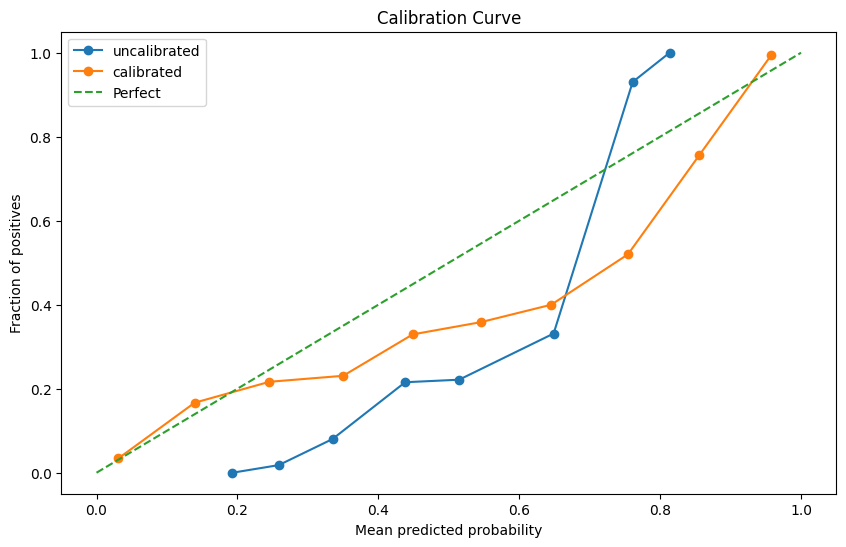

In [ ]:
#Uncalibrated model probabilites

uncalibrated_probabilities = Xgb_model.predict_proba(x_test)[:,1]
uncalibrated_probabilities

calibrated_probabilities = calibrated_model.predict_proba(x_test)[:,1]
calibrated_probabilities

# Pass n_bins to calibration_curve instead of plt.plot
actual_uncalibrated,predicted_uncalibrated = calibration_curve(y_test,uncalibrated_probabilities, n_bins=10)
actual_calibrated,predicted_calibrated = calibration_curve(y_test,calibrated_probabilities, n_bins=10)

plt.figure(figsize = (10,6))
plt.plot(predicted_uncalibrated, actual_uncalibrated, marker='o', label = 'uncalibrated')
plt.plot(predicted_calibrated, actual_calibrated, marker='o', label = 'calibrated')
plt.plot([0, 1], [0, 1], linestyle='--', label='Perfect')

plt.xlabel('Mean predicted probability')
plt.ylabel('Fraction of positives')
plt.title('Calibration Curve')
plt.legend()
plt.show()

In [ ]:
import shap

#get the trained Xgboost classifeire model out of the pipeline

#transform x_test using the same preprocessing used for training

#get feature names after one hot encoding so plot are readable

xgb_classifier = Xgb_model.named_steps['classifier']
xgb_preprocessor = Xgb_model.named_steps['preprocessor']
x_test_transformed = xgb_preprocessor.transform(x_test)

# Correctly retrieve feature names from the ColumnTransformer
feature_names = list(xgb_preprocessor.get_feature_names_out())
feature_names

# Use columns=feature_names instead of passing it positionally as the index
x_test_df = pd.DataFrame(x_test_transformed, columns=feature_names)
x_test_df

In [ ]:
#create shap now

explainer = shap.TreeExplainer(xgb_classifier)
shap_values = explainer.shap_values(x_test_df)
shap_values

#gloabal explanation


shap.summary_plot(shap_values,x_test_df)

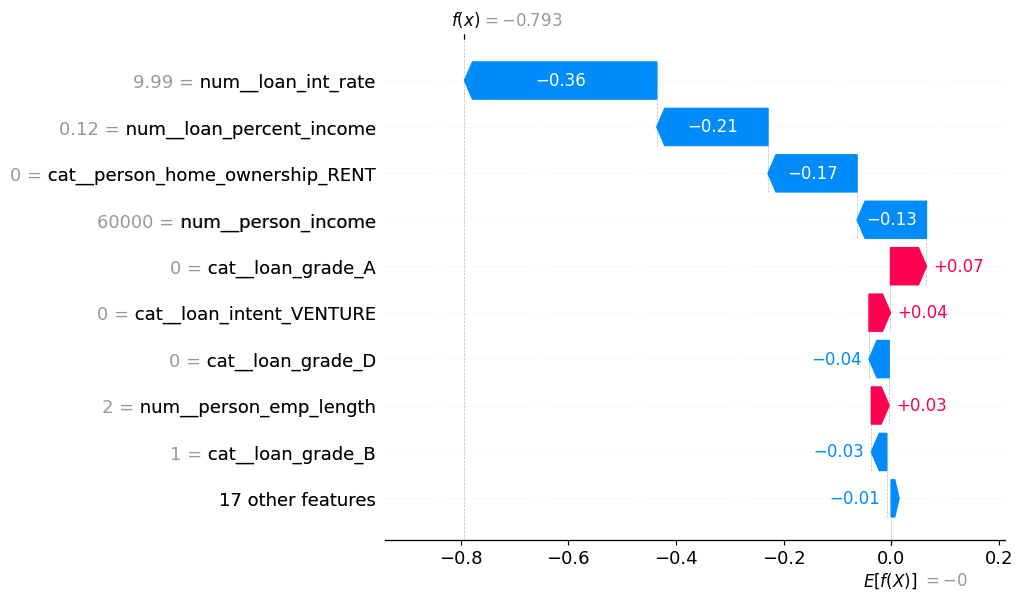

In [ ]:
#shap localexplanation
#pick one row to expalian the 5th applicatnt in the test dataset

row_index = 5

# Create the Explanation object correctly by calling the explainer directly
# This packages values, base_values, and data automatically
explainer_obj = shap.TreeExplainer(xgb_classifier)
shap_values_obj = explainer_obj(x_test_df)

# Draw the waterfall model for the specified row index
shap.plots.waterfall(shap_values_obj[row_index])

In [ ]:
#analayze the false positive and false negative

#false positive safe people marked as negative
#false negative negative  people marked  as positive

# Correctly call predict on the fitted search instance 'random_search' instead of the class name
best_predictions = random_search.predict(x_test)


best_predictions
#create dataframe of xtest to compare
x_test_df = x_test.copy()
x_test_df['prediction'] = best_predictions
x_test_df['actualvalues'] = y_test
x_test_df

In [ ]:
false_positives = x_test_df[ (x_test_df['actualvalues']== 1) & (x_test_df['prediction'] == 0)]
false_positives

false_negatives = x_test_df[ (x_test_df['actualvalues']== 0) & (x_test_df['prediction'] == 1)]
false_negatives

print(f"false_positives:{len(false_positives)}")
print(f"false_negatives:{len(false_negatives)}")

In [ ]:
df_copy.select_dtypes(exclude = 'number').columns